# 11 Ethics and regulation (Part D)

Six deliverables: the Model Card (11.1, also saved as `docs/model_card.md`), metrics by segment (11.2), a proxy check with a mitigation (11.3), a regulatory mapping (11.4), a Findex gap analysis for Ghana (11.5) and a plain-language decline letter (11.6, also `docs/decline_letter.md`).

**Sources actually read for this section:** BoG Digital Credit Directive (Notice 30, Sep 2025), `docs/legal/BoG_Digital_Credit_Directive_Notice30_2025.pdf`; Data Protection Act 2012 (Act 843), `docs/legal/Act843_DataProtectionAct2012.pdf`. The **Credit Reporting Act 2007 (Act 726)** full text could not be obtained (the Parliament repository blocks automated download), so Act 726 obligations below are taken from Act 843 s.36 (which cross-references it) and from secondary descriptions, and are marked *unverified*.

In [1]:
import sys, warnings; sys.path.append(".."); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from src.config import set_seed, FIGURES, DATA_PROCESSED, FINDEX_CSV, ROOT
from src import models as M, validation as V
from src.costs import LoanEconomics
from src.reasons import ReasonCoder
set_seed()
econ = LoanEconomics()
feat = pd.read_pickle(DATA_PROCESSED / "features.pkl")
tr = feat[feat.split == "train"].reset_index(drop=True)
cols = M.inputs(M.DEPLOY_FEATURES)
oof, fid, folds = V.cross_validate(M.logreg(numeric=M.DEPLOY_FEATURES, class_weight=None), tr, cols, V.temporal(tr))
ev = tr[fid >= 0].assign(p=oof[fid >= 0], fold=fid[fid >= 0])
ev["declined"] = ev.p > econ.threshold
print(f"Deployed model, temporal OOF: {len(ev):,} loans, PR-AUC {folds.pr_auc.mean():.3f}, ROC {folds.roc_auc.mean():.3f}")

Deployed model, temporal OOF: 39,894 loans, PR-AUC 0.145, ROC 0.725


## 11.2 Metrics by segment

In [2]:
def seg_metrics(d):
    y, dec = d.target.astype(int), d.declined
    pos, neg = y == 1, y == 0
    auc = roc_auc_score(y, d.p) if pos.sum() >= 10 and neg.sum() >= 10 else np.nan
    return pd.Series({"loans": len(d), "defaults": int(pos.sum()), "default_rate": y.mean(), "mean_pred": d.p.mean(),
                      "decline_rate": dec.mean(), "recall (defaults caught)": dec[pos].mean() if pos.any() else np.nan,
                      "good borrowers declined (FPR)": dec[neg].mean(), "precision": y[dec].mean() if dec.any() else np.nan,
                      "ROC-AUC": auc, "small sample": pos.sum() < 30})

ev["loan_type_g"] = ev.loan_type.where(ev.loan_type.map(ev.loan_type.value_counts()) >= 300, "Other")
ev["size_band"] = pd.qcut(ev.Total_Amount, 5, labels=["Q1 smallest", "Q2", "Q3", "Q4", "Q5 largest"])
ev["history_band"] = pd.cut(ev.n_prev_loans, [-1, 0, 4, 19, 10_000], labels=["0 earlier loans", "1-4", "5-19", "20+"])
ev["new_vs_repeat"] = np.where(ev.is_new == 1, "New Loan", "Repeat Loan")
ev["regime"] = np.where(ev.fold >= 3, "Dec 2022 onward", "2022 boom")
segs = {"country": ev.country_id, "regime": ev.regime, "loan type": ev.loan_type_g, "lender": ev.lender_id,
        "New vs Repeat": ev.new_vs_repeat, "loan size band": ev.size_band, "borrowing history": ev.history_band}
table = pd.concat({k: ev.groupby(v, observed=True).apply(seg_metrics, include_groups=False) for k, v in segs.items()}, names=["segment", "group"])
table.loc[("all", "all"), :] = seg_metrics(ev)
table.to_csv(FIGURES.parent / "11_segment_metrics.csv")
table.style.format(precision=3).background_gradient(subset=["decline_rate", "good borrowers declined (FPR)"], cmap="Reds")

**Reading.**
- **Country.** Every labelled loan is Kenyan, so no Ghana accuracy can be reported. Section 10 gives Ghana's *predicted* decline rate (22%), which is not a performance metric.
- **New vs Repeat and borrowing history** show the largest gaps. Borrowers with no earlier loans default far more often, and the model declines them far more often, including many who would have repaid (a high false-positive rate). On the positive side, recall is also highest there: the model is doing what the data says, but the cost of being a thin-file borrower falls on good thin-file borrowers too.
- **Lender and loan type.** Decline rates differ by an order of magnitude between lenders and products. The model almost never declines Type_1 (0.1%), which is 91% of these loans; nearly all declines fall on the other products, where defaults are 7 to 15%. Part of this is genuine product risk, part is lender book composition, which a borrower cannot control.
- **Loan size.** The largest-loan quintile is declined most, consistent with term and size driving risk.
- Segments flagged *small sample* (fewer than 30 defaults) have unstable rates; treat them as indicative.
- The ROC-AUC column is computed on out-of-fold scores pooled across folds, which Section 7 showed inflates ranking metrics (pooled 0.835 against the fold average of 0.725). Use it only to compare segments with each other.

## 11.3 Proxy check and mitigation

**Direct protected attributes.** The data contains none of the "special personal data" of Act 843 s.37(1) (religion, ethnic origin, race, trade-union membership, political opinions, health, sexual life, criminal behaviour), nor gender, age, income or location. So the model cannot use them directly, **and we cannot measure fairness against them directly** either.

**Candidate proxies.** A feature can stand in for a protected trait if it is strongly associated with it in the population:

| Feature | Could proxy for | Basis |
|---|---|---|
| Borrowing history (`n_prev_loans`, `is_new`, `has_resolved_history`) | Gender, income, education, age, rural residence | Findex 2021 Ghana (11.5): formal and digital borrowing histories are unevenly distributed across these groups |
| Loan amount and past loan sizes | Income | Larger loans go to higher earners |
| Lender and product | Region, channel, occupation | Lenders and products serve different customer bases |

**Test.** The borrowing-history family is the strongest proxy candidate and drives the largest gap in 11.2. We measure what happens if we remove it from the model.

In [3]:
HISTORY_COLS = ["n_prev_loans", "n_prev_resolved", "has_resolved_history", "is_new", "n_prev_lenders", "prev_duration_mean"]
no_hist = [c for c in M.DEPLOY_FEATURES if c not in HISTORY_COLS]
oof_nh, _, folds_nh = V.cross_validate(M.logreg(numeric=no_hist, class_weight=None), tr, M.inputs(no_hist), V.temporal(tr))
ev["p_nohist"] = oof_nh[fid >= 0]

def gap(pcol, thr=econ.threshold):
    d = ev.assign(dec=ev[pcol] > thr)
    g = d.groupby("history_band", observed=True).apply(lambda x: pd.Series({
        "decline_rate": x.dec.mean(), "FPR": x.dec[x.target == 0].mean(), "recall": x.dec[x.target == 1].mean()}), include_groups=False)
    return g

res = pd.concat({"deployed model": gap("p"), "without history features": gap("p_nohist")}, axis=1)
display(res.round(3))
summary = pd.DataFrame({
    "PR-AUC": [folds.pr_auc.mean(), folds_nh.pr_auc.mean()], "ROC-AUC": [folds.roc_auc.mean(), folds_nh.roc_auc.mean()],
    "FPR ratio (0 loans / 20+)": [res[("deployed model", "FPR")].iloc[0] / res[("deployed model", "FPR")].iloc[-1],
                                  res[("without history features", "FPR")].iloc[0] / res[("without history features", "FPR")].iloc[-1]],
}, index=["deployed model", "without history features"])
summary.round(3)

deployed model               without history features         \
                  decline_rate    FPR recall             decline_rate    FPR   
history_band                                                                   
0 earlier loans          0.322  0.296  0.533                    0.298  0.270   
1-4                      0.109  0.101  0.317                    0.116  0.108   
5-19                     0.012  0.010  0.102                    0.021  0.020   
20+                      0.001  0.001  0.022                    0.002  0.002   

                        
                recall  
history_band            
0 earlier loans  0.518  
1-4              0.317  
5-19             0.168  
20+              0.022

,PR-AUC,ROC-AUC,FPR ratio (0 loans / 20+)
deployed model,0.145,0.725,320.453
without history features,0.144,0.720,141.206


**Reading.** Removing the six history features **changes almost nothing**: PR-AUC moves from 0.145 to 0.144, and good borrowers with no earlier loans are still declined about 27% of the time (against 30%), while good borrowers with 20+ loans are almost never declined. The history signal flows back through correlated features: missing past-loan sizes, no recent borrowing, and the absence of any resolved record all identify a thin-file applicant just as well. **Dropping a proxy does not remove it.** Thin-file borrowers genuinely default more in this data (11% against 0.3%), so any accurate model will treat them differently; the question is what NkwaPay does with that score.

**Mitigation we recommend: a thin-file policy rather than a blind model.**
1. Keep history in the model (it reflects real repayment behaviour), but **do not auto-decline** applicants with no repayment record. Route them to a **starter-loan track**: a small capped first loan (the Section 6 regression over-predicts first loans by about 40%, so a cap is needed anyway), with limits that step up after on-time repayment. This builds the history the model lacks, which matters most in Ghana (11.5).
2. **Monitor parity**: track decline rate and good-borrower decline rate (FPR) by history band and New vs Repeat each month, with a review trigger if the FPR ratio exceeds an agreed level.
3. **Collect consented, lawful attributes for auditing only** (gender, age band, region) on a sample, kept separate from the scoring pipeline, so true group fairness can be measured, consistent with Act 843 s.19 (minimality) and s.20 (consent).

## 11.4 Mapping the design to BoG, Act 843 and Act 726

Section numbers are from the documents in `docs/legal/` unless marked *unverified*.

In [4]:
mapping = pd.DataFrame([
    ("BoG Directive §6.1(a), §7.1(3)", "Clear, comprehensive, accurate information; disclose charges, interest, total cost of credit, due date", "Decline letter (11.6) and reason codes state the decision and its main factors in plain language; the cost model uses disclosed flat, non-compounded pricing", "Partly. Pricing disclosure is a product task outside the model"),
    ("BoG Directive §6.1(b)", "Digital pre-agreement: principal, disbursement schedule, cost of default, fees, insurance", "Scoring service returns the approved limit; pre-agreement content is outside the model", "Not met by the model; product must supply it"),
    ("BoG Directive §6.1(c), §7.1(3)(b)", "Interest disclosed for the tenure, not compounded", "Cost matrix (src/costs.py) uses a flat fee rate; no compounding", "Met in our assumptions"),
    ("BoG Directive §6.1(e)", "Complaint receipt and resolution within twenty days", "Decline letter gives a complaint channel and the 20-day commitment", "Met in the letter; NkwaPay must run the process"),
    ("BoG Directive §7.2", "No harassment, threats, or contacting a customer's contacts during collection", "The model uses no contact-list or social data, and recovery assumptions do not rely on such tactics", "Met for the model"),
    ("BoG Directive §7.3(5)-(9)", "Submit customer credit information to licensed bureaus daily, with prior customer consent", "Not in scope of the model; bureau data is recommended as a future feature (Part C)", "Not met: no bureau integration in our system"),
    ("Act 843 s.17-18", "Accountability, lawful and reasonable processing, purpose specification, openness, security, participation", "Model Card documents purpose, data and limits; features are restricted to loan application and repayment records", "Partly. Security and accountability processes are organisational"),
    ("Act 843 s.19", "Minimality: processing necessary, relevant and not excessive", "Calendar and macro features removed (no predictive value); leaky columns dropped; no special or social data used", "Met for model inputs"),
    ("Act 843 s.20, s.22-23", "Consent or lawful basis; specific purpose; data subject made aware", "Credit assessment is necessary for the contract (s.20(1)(a)); notice of purpose is in the letter", "Partly. Consent capture is a product task"),
    ("Act 843 s.26", "Quality of information: complete, accurate, up to date", "Leakage audit (Section 1) found Total_Amount_to_Repay updated after default; excluded", "Met for inputs we audited"),
    ("Act 843 s.32-33, s.35", "Access to personal data; correction of inaccurate data", "Letter tells the applicant how to request their data and correct errors; reason codes show which records drove the decision", "Met in the letter; NkwaPay must handle requests"),
    ("Act 843 s.37", "Special personal data (religion, ethnicity, race, health, politics, etc.) not processed", "None used; proxies checked in 11.3", "Met; proxy risk monitored"),
    ("Act 843 s.41", "Automated decisions that significantly affect a person: notify, and reconsider on request within 21 days; s.41(4)(a)-(b) exempts decisions about entering into a contract", "Credit approval arguably falls under the contract exemption, but we design as if s.41 applies: the letter notifies the automated basis and offers human reconsideration within 21 days", "Met by design (stronger than the minimum)"),
    ("Act 843 s.36 / Act 726 (unverified sections)", "Credit-bureau data subject rights; retention under Act 726 s.30 (as cited in Act 843 s.36)", "No bureau data used yet", "Not applicable until bureau integration; text of Act 726 not reviewed"),
    ("Act 726 (unverified; reported s.26)", "Reportedly: lenders must obtain a credit report before granting credit", "Our model does not query a bureau", "Likely not met; must be confirmed against the Act's text"),
    ("BoG Directive §7.1(1)", "Digital credit policy in line with the Borrowers and Lenders Act 2020 (Act 1052)", "Not reviewed", "Unknown; Act 1052 not reviewed"),
], columns=["Requirement", "What it asks", "How our design responds", "Status"])
mapping.to_csv(FIGURES.parent / "11_regulatory_mapping.csv", index=False)
pd.set_option("display.max_colwidth", 200); mapping

,Requirement,What it asks,How our design responds,Status
0,"BoG Directive §6.1(a), §7.1(3)","Clear, comprehensive, accurate information; disclose charges, interest, total cost of credit, due date","Decline letter (11.6) and reason codes state the decision and its main factors in plain language; the cost model uses disclosed flat, non-compounded pricing",Partly. Pricing disclosure is a product task outside the model
1,BoG Directive §6.1(b),"Digital pre-agreement: principal, disbursement schedule, cost of default, fees, insurance",Scoring service returns the approved limit; pre-agreement content is outside the model,Not met by the model; product must supply it
2,"BoG Directive §6.1(c), §7.1(3)(b)","Interest disclosed for the tenure, not compounded",Cost matrix (src/costs.py) uses a flat fee rate; no compounding,Met in our assumptions
3,BoG Directive §6.1(e),Complaint receipt and resolution within twenty days,Decline letter gives a complaint channel and the 20-day commitment,Met in the letter; NkwaPay must run the process
4,BoG Directive §7.2,"No harassment, threats, or contacting a customer's contacts during collection","The model uses no contact-list or social data, and recovery assumptions do not rely on such tactics",Met for the model
5,BoG Directive §7.3(5)-(9),"Submit customer credit information to licensed bureaus daily, with prior customer consent",Not in scope of the model; bureau data is recommended as a future feature (Part C),Not met: no bureau integration in our system
6,Act 843 s.17-18,"Accountability, lawful and reasonable processing, purpose specification, openness, security, participation","Model Card documents purpose, data and limits; features are restricted to loan application and repayment records",Partly. Security and accountability processes are organisational
7,Act 843 s.19,"Minimality: processing necessary, relevant and not excessive",Calendar and macro features removed (no predictive value); leaky columns dropped; no special or social data used,Met for model inputs
8,"Act 843 s.20, s.22-23",Consent or lawful basis; specific purpose; data subject made aware,Credit assessment is necessary for the contract (s.20(1)(a)); notice of purpose is in the letter,Partly. Consent capture is a product task
9,Act 843 s.26,"Quality of information: complete, accurate, up to date",Leakage audit (Section 1) found Total_Amount_to_Repay updated after default; excluded,Met for inputs we audited


**What we cannot meet with the model alone.**
1. **Credit bureau checks and reporting.** BoG Directive §7.3 requires daily, consented submission to licensed bureaus, and Act 726 reportedly requires a credit report before lending. Our system has no bureau link.
2. **Ghana-specific validity.** No Ghanaian outcomes exist, so we cannot show the model is accurate or fair for Ghanaian applicants (Part C), which undermines the "accurate information" duties for Ghana.
3. **Group fairness against protected traits.** Without lawful, consented demographic data we can only test proxies.
4. **Organisational duties** (registration as a data controller, s.27; security, s.28; breach notification, s.31; complaint handling, Directive §6.1(e)) depend on NkwaPay's processes, not the model.
5. **Act 726 and Act 1052** were not reviewed from their texts; the mapping for them must be confirmed by a lawyer.

## 11.5 Findex 2021: who in Ghana is likely to be thin-file?

In [5]:
fx = pd.read_csv(FINDEX_CSV, encoding_errors="replace")
# Findex 2021 codes: female 1 = female, 2 = male; educ 1 = primary or less, 2 = secondary, 3 = tertiary;
# inc_q 1 = poorest 20% ... 5 = richest 20%; urbanicity_f2f 1 = rural, 2 = urban; fin22a/fin22c 1 = yes
fx["gender"] = fx.female.map({1: "women", 2: "men"})
fx["education"] = fx.educ.map({1: "primary or less", 2: "secondary", 3: "tertiary"})
fx["income"] = fx.inc_q.map({1: "poorest 40%", 2: "poorest 40%", 3: "richest 60%", 4: "richest 60%", 5: "richest 60%"})
fx["age_band"] = pd.cut(fx.age, [14, 24, 34, 49, 120], labels=["15-24", "25-34", "35-49", "50+"])
fx["area"] = fx.urbanicity_f2f.map({1: "rural", 2: "urban"})
fx["borrowed_formal"] = (fx.fin22a == 1).astype(int)
fx["borrowed_mobile"] = (fx.fin22c == 1).astype(int)       # asked of mobile money account owners; others count as no
inds = {"account": "Any account", "account_fin": "Financial institution account", "account_mob": "Mobile money account",
        "borrowed": "Borrowed any money (12 months)", "borrowed_formal": "Borrowed from a formal institution", "borrowed_mobile": "Borrowed via mobile money"}

def wshare(d, col):
    w = d.wgt
    p = np.average(d[col], weights=w)
    n_eff = w.sum() ** 2 / (w ** 2).sum()
    return p, 1.96 * np.sqrt(p * (1 - p) / n_eff)

rows = []
for grp in ["all", "gender", "income", "education", "age_band", "area"]:
    levels = [("all", fx)] if grp == "all" else [(lv, d) for lv, d in fx.groupby(grp, observed=True)]
    for lv, d in levels:
        r = {"group": grp, "level": lv, "n": len(d)}
        for c, lab in inds.items():
            p, h = wshare(d, c); r[lab] = p; r[lab + " ±"] = h
        rows.append(r)
gapt = pd.DataFrame(rows).set_index(["group", "level"])
gapt.to_csv(FIGURES.parent / "11_findex_gaps.csv")
gapt[["n"] + list(inds.values())].round(3)

n  Any account  Financial institution account  \
group     level                                                               
all       all              1000        0.682                          0.392   
gender    men               535        0.742                          0.473   
          women             465        0.626                          0.315   
income    poorest 40%       309        0.547                          0.248   
          richest 60%       691        0.772                          0.488   
education primary or less   295        0.516                          0.239   
          secondary         638        0.795                          0.472   
          tertiary           64        0.983                          0.952   
age_band  15-24             291        0.652                          0.285   
          25-34             375        0.758                          0.481   
          35-49             226        0.675                          0.384   
          50+               104        0.654                          0.457   
area      rural             360        0.565                          0.268   
          urban             640        0.761                          0.475   

                           Mobile money account  \
group     level                                   
all       all                             0.597   
gender    men                             0.646   
          women                           0.550   
income    poorest 40%                     0.464   
          richest 60%                     0.685   
education primary or less                 0.429   
          secondary                       0.711   
          tertiary                        0.907   
age_band  15-24                           0.616   
          25-34                           0.698   
          35-49                           0.590   
          50+                             0.465   
area      rural                           0.479   
          urban                           0.676   

                           Borrowed any money (12 months)  \
group     level                                             
all       all                                       0.522   
gender    men                                       0.567   
          women                                     0.479   
income    poorest 40%                               0.521   
          richest 60%                               0.523   
education primary or less                           0.503   
          secondary                                 0.533   
          tertiary                                  0.620   
age_band  15-24                                     0.495   
          25-34                                     0.533   
          35-49                                     0.579   
          50+                                       0.466   
area      rural                                     0.520   
          urban                                     0.524   

                           Borrowed from a formal institution  \
group     level                                                 
all       all                                           0.072   
gender    men                                           0.090   
          women                                         0.056   
income    poorest 40%                                   0.049   
          richest 60%                                   0.088   
education primary or less                               0.047   
          secondary                                     0.074   
          tertiary                                      0.320   
age_band  15-24                                         0.045   
          25-34                                         0.068   
          35-49                                         0.091   
          50+                                           0.096   
area      rural                                         0.066

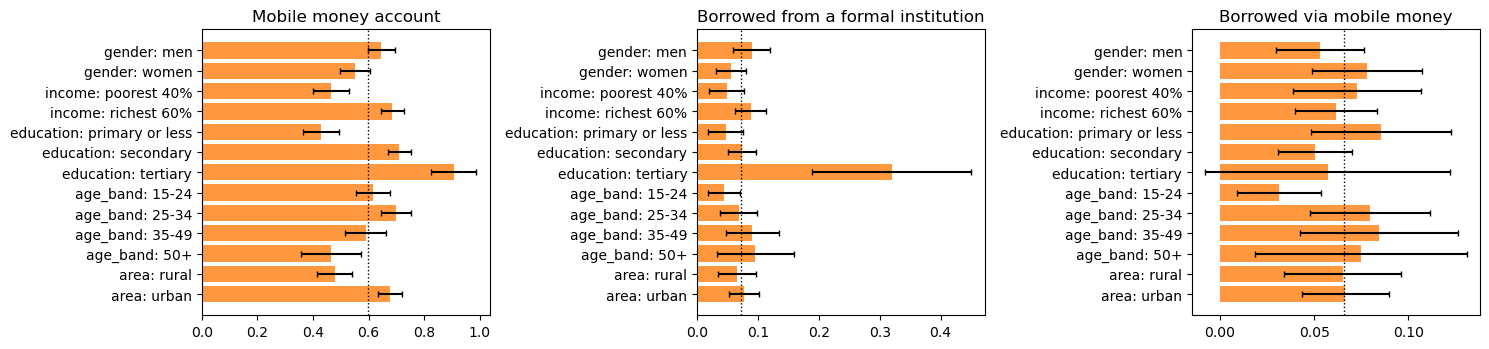

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=False)
for ax, lab in zip(axes, ["Mobile money account", "Borrowed from a formal institution", "Borrowed via mobile money"]):
    g = gapt.drop(index="all", level=0)
    yy = np.arange(len(g))
    ax.barh(yy, g[lab], xerr=g[lab + " ±"], color="tab:orange", alpha=.8, capsize=2)
    ax.axvline(gapt.loc[("all", "all"), lab], c="k", ls=":", lw=1)
    ax.set_yticks(yy, [f"{a}: {b}" for a, b in g.index]); ax.set_title(lab); ax.invert_yaxis()
plt.tight_layout(); plt.savefig(FIGURES / "11_findex_gaps.png", dpi=200); plt.show()

**Reading (survey-weighted, 95% intervals from the Kish effective sample size; about 1,000 respondents, so subgroup gaps of a few points are within noise).**
- **Mobile money is widespread, formal borrowing is rare.** 60% of adults have a mobile money account, but only 7% borrowed from a formal institution and 7% via mobile money in the past year, while 52% borrowed *some* money, mostly informally. Demand for credit is broad; formal records are thin.
- **Account gaps are large and clear:** women 63% against men 74%; poorest 40% at 55% against 77%; primary education or less 52% against 80% for secondary; rural 57% against 76%.
- **Formal borrowing** is lower for women (5.6% against 9.0%), the poorest (4.9% against 8.8%), the least educated and the youngest, though most of these intervals overlap.
- **Borrowing via mobile money is not lower for these groups**; the point estimates are slightly *higher* for women, the poorest and the least educated (within noise). Digital credit is already reaching them, and they arrive with little formal history.
- **Link to the model.** The deployed model's strongest proxy is borrowing history (11.3), and it declines a third of applicants with no earlier loans. In Ghana, the people most likely to be new to formal credit are women, poorer, less educated, younger and rural adults, and they are already digital-credit users. Without the thin-file policy, the model would likely decline these groups disproportionately even though no protected attribute is in it.
- **Caveat.** Findex describes the adult population, not NkwaPay's applicants, and it measures access, not repayment. It shows where the proxy risk lies; only pilot data with consented demographics can show the actual effect.

## 11.6 Plain-language decline letter

In [7]:
model = M.logreg(numeric=M.DEPLOY_FEATURES, class_weight=None).fit(tr[cols], tr.target)
rc = ReasonCoder(model).fit(tr[cols])
te = feat[(feat.split == "test") & (feat.country_id == "Kenya")].reset_index(drop=True)
te["p"] = model.predict_proba(te[cols])[:, 1]
cand = te[(te.p > econ.threshold) & (te.p < 0.2)]
app = cand.iloc[[0]]
reasons = rc.top_reasons(app[cols])[0]

def decline_letter(name, reasons, p):
    bullets = "\n".join(f"- {r['text']}" for r in reasons)
    return f'''Dear {name},

Thank you for applying for a loan with NkwaPay. We are sorry to tell you that we cannot approve this application at this time.

**Why.** Your application was assessed by an automated scoring system that estimates how likely a loan is to be repaid on time, using the details of this application and your past loans with us. It does not use your religion, ethnicity, health, political opinions or any other sensitive personal information. The main reasons for this decision were:

{bullets}

**What you can do.**
- **Ask for a person to review this decision.** Reply to this message or call our support line within 21 days and a member of our team, not the automated system, will look at your application again and tell you in writing what we will do.
- **Try a smaller or shorter loan.** Shorter repayment periods and smaller first loans are approved more often, and repaying on time helps future applications.
- **Check the information we hold about you.** You can ask to see the personal data we used and ask us to correct anything that is wrong or out of date.
- **Make a complaint.** If you are unhappy with how we handled your application, contact our complaints team. We will resolve your complaint within 20 days. You can also contact the Data Protection Commission or the Bank of Ghana.

This decision is about this application only. It is not a judgement about you, and it does not stop you applying again.

Yours sincerely,
NkwaPay Customer Care

*Reference: application {app.tbl_loan_id.iloc[0]} (model score {p:.0%}; internal use)*'''

letter = decline_letter("Customer", reasons, float(app.p.iloc[0]))
(ROOT / "docs" / "decline_letter.md").write_text("# Example decline letter\n\n" + letter + "\n")
from IPython.display import Markdown; Markdown(letter)

Dear Customer,

Thank you for applying for a loan with NkwaPay. We are sorry to tell you that we cannot approve this application at this time.

**Why.** Your application was assessed by an automated scoring system that estimates how likely a loan is to be repaid on time, using the details of this application and your past loans with us. It does not use your religion, ethnicity, health, political opinions or any other sensitive personal information. The main reasons for this decision were:

- Loans of this product type have had higher repayment problems.
- Your recent borrowing pattern (time since your last loan and loans currently running) differs from that of borrowers who usually repay.
- The sizes of your previous loans are in a range where repayment problems have been more common.

**What you can do.**
- **Ask for a person to review this decision.** Reply to this message or call our support line within 21 days and a member of our team, not the automated system, will look at your application again and tell you in writing what we will do.
- **Try a smaller or shorter loan.** Shorter repayment periods and smaller first loans are approved more often, and repaying on time helps future applications.
- **Check the information we hold about you.** You can ask to see the personal data we used and ask us to correct anything that is wrong or out of date.
- **Make a complaint.** If you are unhappy with how we handled your application, contact our complaints team. We will resolve your complaint within 20 days. You can also contact the Data Protection Commission or the Bank of Ghana.

This decision is about this application only. It is not a judgement about you, and it does not stop you applying again.

Yours sincerely,
NkwaPay Customer Care

*Reference: application 104034 (model score 8%; internal use)*

**Design choices.** Short sentences and everyday words; the decision first; reasons in the applicant's terms (from `src/reasons.py`, never calendar or sensitive data); concrete next steps. The 21-day human review reflects Act 843 s.41(2)-(3) (applied even though the contract exemption in s.41(4) may cover credit decisions), access and correction reflect s.32-33, and the 20-day complaint commitment reflects BoG Directive §6.1(e). For Ghana applicants with an unseen product, the reason reads "This product type is new to us, so we have no repayment record for it yet", which is true and invites review rather than implying a bad record. The letter should be offered in English and the main local languages, and by SMS in a shortened form with a link to the full text.

## 11.1 Model Card

In [8]:
f = folds
card = f'''# Model Card: NkwaPay default-risk classifier (v1, ICS553 Prosit 2)

## Model details
- **Type:** logistic regression (scikit-learn, L2, C = 1, unweighted), with median imputation plus missing-value indicators, standardisation, and one-hot product and lender (levels with fewer than 30 training loans grouped as Other, unseen levels as Unknown).
- **Inputs (deployed set):** loan terms (log amount, term, amount per day, lender share, number of co-funders, New/Repeat flag), borrower history from earlier loans only (counts, observable past defaults, active loans, past amounts and terms, distinct lenders), product and lender. Calendar and macro features excluded. Full list: `src/models.py::DEPLOY_FEATURES`.
- **Output:** probability of default; decision rule decline if P(default) > {econ.threshold:.3f} (from the cedi cost matrix, `src/costs.py`); top three reason codes (`src/reasons.py`).
- **Companion model:** ridge regression for a loan-size limit on repaid loans (Section 6).
- **Owners:** ICS553 group 3. Date: November 2026.

## Intended use
- Ranking and screening **Kenyan** digital loan applications similar to those in the training data, with human review of declines on request.
- **Not intended for:** automated decisions in Ghana or any market without local outcome data; decisions about people with no relationship to the products and lenders seen in training; any use other than credit assessment.

## Training data
- Zindi African Credit Scoring Challenge, Kenya, Oct 2021 to Nov 2024: {len(tr):,} loans after merging co-funded rows, 1.63% default.
- Excluded as leakage: Total_Amount_to_Repay and Lender_portion_to_be_repaid (updated after default).
- No protected or special personal data (Act 843 s.37).

## Evaluation (temporal expanding-window CV, 5 folds)
- PR-AUC {f.pr_auc.mean():.3f}, ROC-AUC {f.roc_auc.mean():.3f} (fold average). Bootstrap 95% interval for PR-AUC about ±0.025 (Section 7).
- 2022 boom regime: ROC about 0.78. From Dec 2022: ROC about 0.64, PR-AUC lift about 1.8 over base rate.
- Beats the approve-everyone baseline on every metric and in cedis; not distinguishable from shallow LightGBM on PR-AUC overall.
- Calibration: good in the 2022 regime; over-spread after Dec 2022 (low scores too low, high scores too high).

## Segment performance (Section 11.2)
- Largest gaps by borrowing history and New vs Repeat: thin-file borrowers are declined far more often, including many who would repay.
- Decline rates differ by lender and product by an order of magnitude.

## Ethical considerations
- Borrowing history is a likely proxy for gender, income, education, age and rural residence in Ghana (Findex 2021, Section 11.5).
- Mitigation: no automatic decline for thin-file applicants; capped starter loans; monthly parity monitoring by history band; consented demographic sample for audits.
- Reason codes are relative to the average applicant, not counterfactuals; product and lender reasons are not actionable by the borrower.

## Caveats and recommendations
- **Ghana:** 87% of Ghana loans are on unseen products and 96% on unseen lenders; a domain classifier separates Ghana from Kenya with AUC 1.0. Do not use for automated Ghana decisions until pilot outcomes allow recalibration and validation (Section 10).
- **Drift:** performance roughly halved after Dec 2022. Recalibrate monthly on recent outcomes and monitor approval rate, default rate and mean prediction.
- **Regulation:** no credit-bureau integration (BoG Directive §7.3; Act 726 reportedly requires a credit report). Act 726 and Act 1052 not reviewed from primary text.
- Cost-matrix figures are assumptions; replace with NkwaPay's own.
'''
(ROOT / "docs" / "model_card.md").write_text(card)
print(card)

# Model Card: NkwaPay default-risk classifier (v1, ICS553 Prosit 2)

## Model details
- **Type:** logistic regression (scikit-learn, L2, C = 1, unweighted), with median imputation plus missing-value indicators, standardisation, and one-hot product and lender (levels with fewer than 30 training loans grouped as Other, unseen levels as Unknown).
- **Inputs (deployed set):** loan terms (log amount, term, amount per day, lender share, number of co-funders, New/Repeat flag), borrower history from earlier loans only (counts, observable past defaults, active loans, past amounts and terms, distinct lenders), product and lender. Calendar and macro features excluded. Full list: `src/models.py::DEPLOY_FEATURES`.
- **Output:** probability of default; decision rule decline if P(default) > 0.062 (from the cedi cost matrix, `src/costs.py`); top three reason codes (`src/reasons.py`).
- **Companion model:** ridge regression for a loan-size limit on repaid loans (Section 6).
- **Owners:** ICS553 group 3